  [Note] SatCTTA-Plus-5-LOO1 [ue2]: 1782/1782 rows dropped (NaN UE, e.g. trigger range missed)
  [Skip] SatCTTA-Plus-5-LOO1 [ue2]: fewer than 2 valid rows


  [Note] SatCTTA-Plus-5-LOO2 [ue2]: 1782/1782 rows dropped (NaN UE, e.g. trigger range missed)
  [Skip] SatCTTA-Plus-5-LOO2 [ue2]: fewer than 2 valid rows


  [Note] SatCTTA-Cross-5-LOO1 [ue2]: 1782/1782 rows dropped (NaN UE, e.g. trigger range missed)
  [Skip] SatCTTA-Cross-5-LOO1 [ue2]: fewer than 2 valid rows


  [Note] SatCTTA-Cross-5-LOO2 [ue2]: 1782/1782 rows dropped (NaN UE, e.g. trigger range missed)
  [Skip] SatCTTA-Cross-5-LOO2 [ue2]: fewer than 2 valid rows


  [Note] SatCTTA-Rand-5-LOO1 [ue2]: 1782/1782 rows dropped (NaN UE, e.g. trigger range missed)
  [Skip] SatCTTA-Rand-5-LOO1 [ue2]: fewer than 2 valid rows


  [Note] SatCTTA-Rand-5-LOO2 [ue2]: 1782/1782 rows dropped (NaN UE, e.g. trigger range missed)
  [Skip] SatCTTA-Rand-5-LOO2 [ue2]: fewer than 2 valid rows


  [Note] SatCTTA-Plus5-X4Cross-UE2LOO2 [ue2]: 1657/1782 rows dropped (NaN UE, e.g. trigger range missed)


  [Note] SatCTTA-Rand5-R4Rand-UE2LOO2 [ue2]: 1679/1782 rows dropped (NaN UE, e.g. trigger range missed)



[Success] Calibration results exported to: calibrated_thresholds_results_ue1_ue2_WACC@7.0.xlsx

Calibrated Threshold Summary:
 thresh      wacc   tp  tn  fp  fn  accuracy  precision    recall        f1                                      method ue_col  n_valid  n_dropped  avg_ue_total  avg_ue_true  avg_ue_false  rank
    6.5 91.189675 1480 181   6 115 93.209877  99.596231 92.789969 96.072704 SatCTTA-Plus5-X4Cross-fullcov-UE2LOO2 [ue2]    ue2     1782          0      3.565037     2.038185     16.588187     1
    2.5 90.235690 1477 179   8 118 92.929293  99.461279 92.601881 95.909091                   SatCTTA-Cross-5-LOO2 [ue]     ue     1782          0      1.983400     0.943777     10.850774     2
    2.0 90.235690 1449 183   4 146 91.582492  99.724708 90.846395 95.078740                    SatCTTA-Plus-5-LOO2 [ue]     ue     1782          0      1.627119     0.764737      8.982735     3
    5.5 90.067340 1509 174  13  86 94.444444  99.145861 94.608150 96.823869                    Sa

C:\Users\Hesam\AppData\Local\Temp\ipykernel_5032\710111853.py:449: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout()


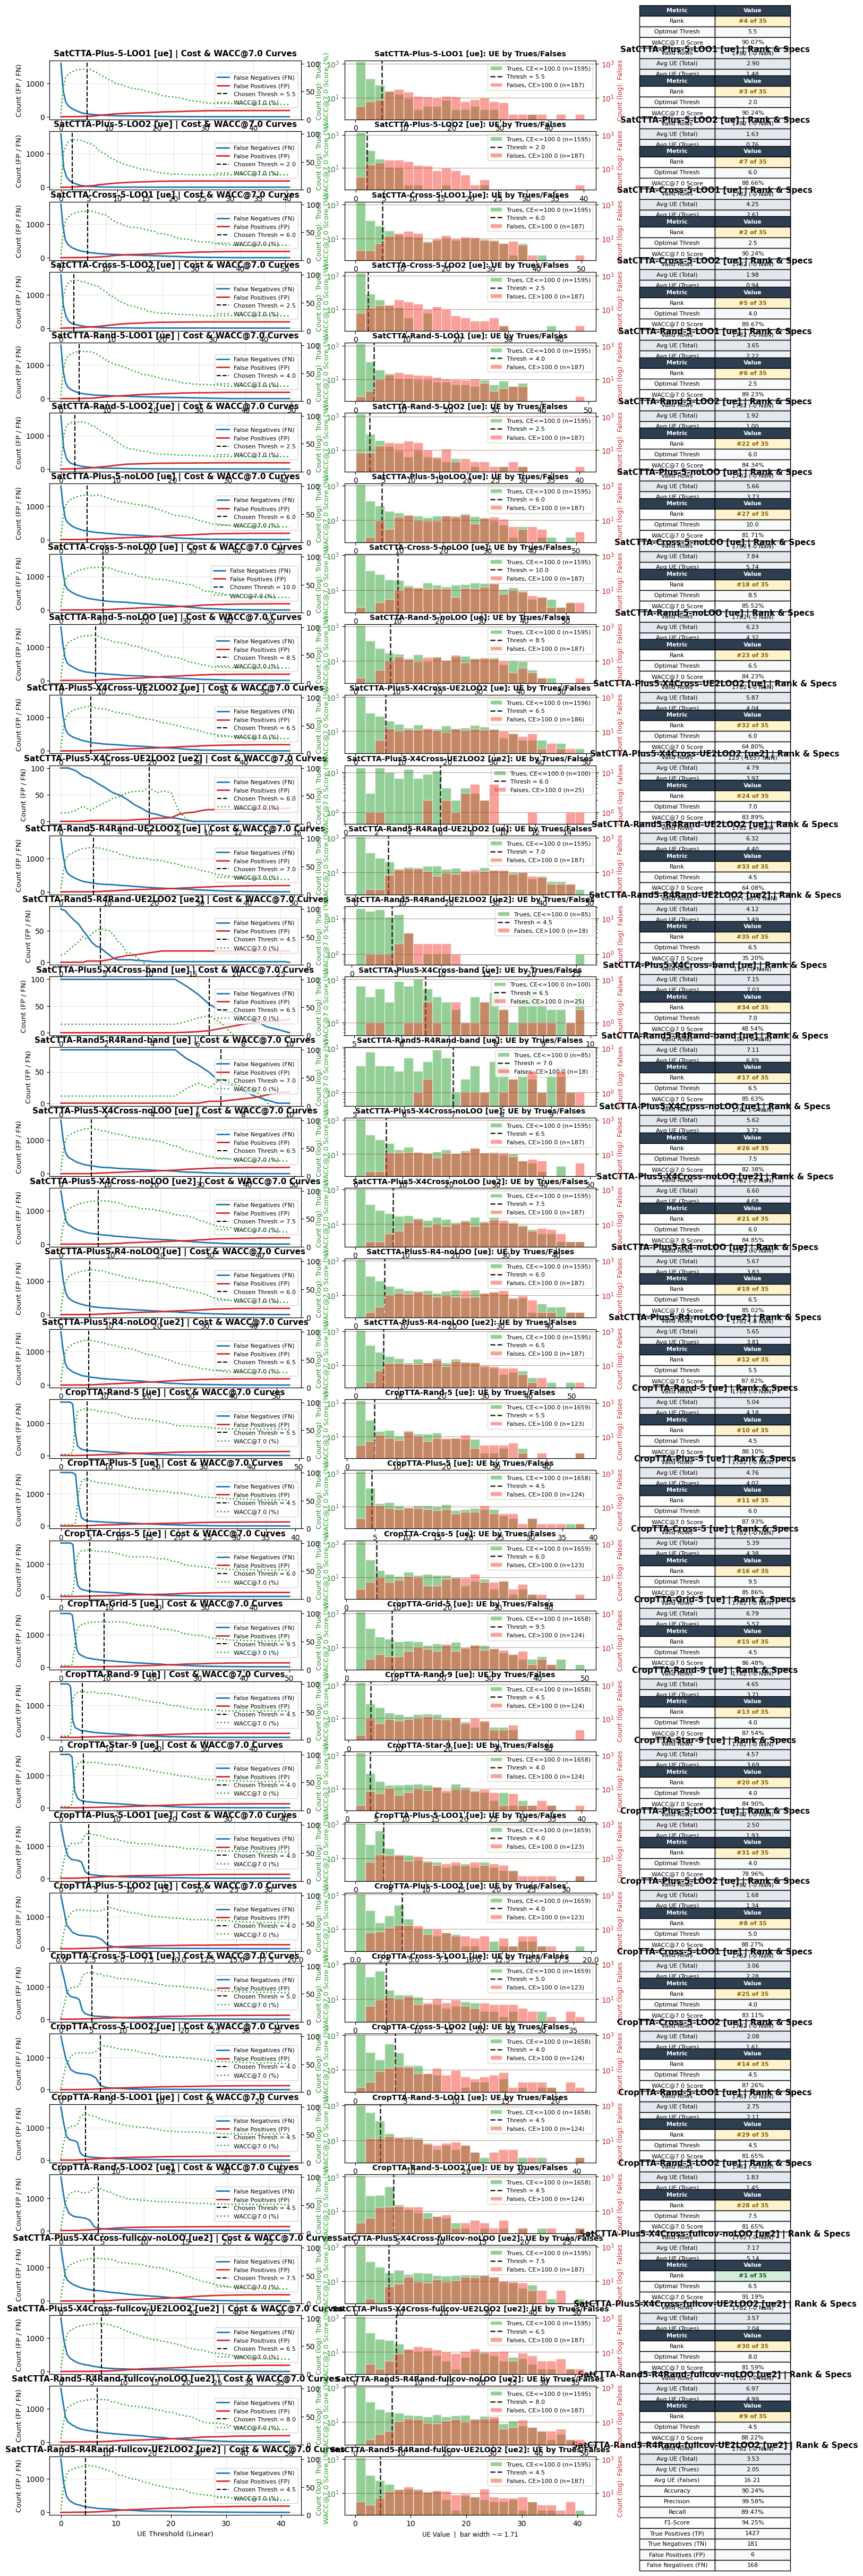

[Success] Updated 3-Column plot exported to: ue_threshold_calibration_ue1_ue2_WACC@7.0.png


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==============================================================================
# INPUT CONFIGURATION
# ==============================================================================
# Each method is calibrated once per UE column in UE_COLUMNS ('ue' = primary
# uncertainty, 'ue2' = secondary uncertainty). Methods whose Excel file lacks a
# column (or whose rows are all NaN for it, e.g. trigger range missed) are
# skipped for that column with an explicit note.
METHODS = {
    # Task 1: primary crop patterns with UE1 LOO outlier removal (no secondary pass)
    'SatCTTA-Plus-5-LOO1':  'js_datasets/Heydar-1746/satcrop-5_plus-ue1-loo1.xlsx',
    'SatCTTA-Plus-5-LOO2':  'js_datasets/Heydar-1746/satcrop-5_plus-ue1-loo2.xlsx',
    'SatCTTA-Cross-5-LOO1': 'js_datasets/Heydar-1746/satcrop-5_cross-ue1-loo1.xlsx',
    'SatCTTA-Cross-5-LOO2': 'js_datasets/Heydar-1746/satcrop-5_cross-ue1-loo2.xlsx',
    'SatCTTA-Rand-5-LOO1':  'js_datasets/Heydar-1746/satcrop-5_rand-ue1-loo1.xlsx',
    'SatCTTA-Rand-5-LOO2':  'js_datasets/Heydar-1746/satcrop-5_rand-ue1-loo2.xlsx',
    # No-removal baselines recomputed from the SAME stored 5-crop predictions
    # (the *_ue1-loo*.xlsx files store every per-crop prediction, so the LOO-free
    #  ue is recoverable exactly; baseline vs LOO stay on identical predictions)
    'SatCTTA-Plus-5-noLOO':  {'path': 'js_datasets/Heydar-1746/satcrop-5_plus-ue1-loo1.xlsx',  'recompute': 'ue1', 'ue_cols': ['ue']},
    'SatCTTA-Cross-5-noLOO': {'path': 'js_datasets/Heydar-1746/satcrop-5_cross-ue1-loo1.xlsx', 'recompute': 'ue1', 'ue_cols': ['ue']},
    'SatCTTA-Rand-5-noLOO':  {'path': 'js_datasets/Heydar-1746/satcrop-5_rand-ue1-loo1.xlsx',  'recompute': 'ue1', 'ue_cols': ['ue']},
    # Task 2: secondary crops + UE2 LOO with trigger range 5-10
    'SatCTTA-Plus5-X4Cross-UE2LOO2': 'js_datasets/Heydar-1746/satcrop-5_plus-4cross-ue2-loo2_trig5-10.xlsx',
    'SatCTTA-Rand5-R4Rand-UE2LOO2':  'js_datasets/Heydar-1746/satcrop-5_rand-4rand-ue2-loo2_trig5-10.xlsx',
    # Stage-1 ue restricted to the SAME in-band rows (fair band comparison)
    'SatCTTA-Plus5-X4Cross-band': {'path': 'js_datasets/Heydar-1746/satcrop-5_plus-4cross-ue2-loo2_trig5-10.xlsx', 'subset': 'band', 'ue_cols': ['ue']},
    'SatCTTA-Rand5-R4Rand-band':  {'path': 'js_datasets/Heydar-1746/satcrop-5_rand-4rand-ue2-loo2_trig5-10.xlsx',  'subset': 'band', 'ue_cols': ['ue']},
    # Baselines: same primary + secondary setups WITHOUT any LOO (trigger 0-1000)
    'SatCTTA-Plus5-X4Cross-noLOO': 'js_datasets/Heydar-1746/satcrop-5_plus_rnd_210-4_crops_cross.xlsx',
    'SatCTTA-Plus5-R4-noLOO':      'js_datasets/Heydar-1746/satcrop-5_plus_rnd_210-4_crops_rnd.xlsx',
    # CropTTA (paper-pattern thermal crops) baselines - deck slide "comparison
    # with paper crops". Offset (105,105) resolves from OFFSETS below.
    'CropTTA-Rand-5':  {'path': 'js_datasets/Heydar-1746/thcrop_4r-google-1536_regen.xlsx', 'ue_cols': ['ue']},
    'CropTTA-Plus-5':  {'path': 'js_datasets/Heydar-1746/thcrop_4p-google-1536_v2.xlsx',    'ue_cols': ['ue']},
    'CropTTA-Cross-5': {'path': 'js_datasets/Heydar-1746/thcrop_4x-google-1536_v2.xlsx',    'ue_cols': ['ue']},
    'CropTTA-Grid-5':  {'path': 'js_datasets/Heydar-1746/thcrop_4g-google-1536_v2.xlsx',    'ue_cols': ['ue']},
    'CropTTA-Rand-9':  {'path': 'js_datasets/Heydar-1746/thcrop_8r-google-1536_v2.xlsx',    'ue_cols': ['ue']},
    'CropTTA-Star-9':  {'path': 'js_datasets/Heydar-1746/thcrop_8px-google-1536_v2.xlsx',   'ue_cols': ['ue']},
    # CropTTA UE1-LOO runs (Task 1 on thermal crops)
    'CropTTA-Plus-5-LOO1':  {'path': 'js_datasets/Heydar-1746/thcrop-5_plus-ue1-loo1.xlsx',   'ue_cols': ['ue']},
    'CropTTA-Plus-5-LOO2':  {'path': 'js_datasets/Heydar-1746/thcrop-5_plus-ue1-loo2.xlsx',   'ue_cols': ['ue']},
    'CropTTA-Cross-5-LOO1': {'path': 'js_datasets/Heydar-1746/thcrop-5_cross-ue1-loo1.xlsx',  'ue_cols': ['ue']},
    'CropTTA-Cross-5-LOO2': {'path': 'js_datasets/Heydar-1746/thcrop-5_cross-ue1-loo2.xlsx',  'ue_cols': ['ue']},
    'CropTTA-Rand-5-LOO1':  {'path': 'js_datasets/Heydar-1746/thcrop-5_random-ue1-loo1.xlsx', 'ue_cols': ['ue']},
    'CropTTA-Rand-5-LOO2':  {'path': 'js_datasets/Heydar-1746/thcrop-5_random-ue1-loo2.xlsx', 'ue_cols': ['ue']},
    # Full-coverage ue2 (all 1782 samples). Stored ue2 of the rand fullcov run is
    # already LOO2; the no-removal / LOO2 series are recomputed from stored
    # per-crop predictions with the verified pool mapping.
    'SatCTTA-Plus5-X4Cross-fullcov-noLOO':   {'path': 'js_datasets/Heydar-1746/satcrop-5_plus_rnd_210-4_crops_cross.xlsx', 'recompute': 'ue2', 'loo_n': 0, 'ue_cols': ['ue2']},
    'SatCTTA-Plus5-X4Cross-fullcov-UE2LOO2': {'path': 'js_datasets/Heydar-1746/satcrop-5_plus_rnd_210-4_crops_cross.xlsx', 'recompute': 'ue2', 'loo_n': 2, 'ue_cols': ['ue2']},
    'SatCTTA-Rand5-R4Rand-fullcov-noLOO':    {'path': 'js_datasets/Heydar-1746/satcrop-5_rand-4rand-fullcov-ue2-loo2.xlsx', 'recompute': 'ue2', 'loo_n': 0, 'ue_cols': ['ue2']},
    'SatCTTA-Rand5-R4Rand-fullcov-UE2LOO2':  {'path': 'js_datasets/Heydar-1746/satcrop-5_rand-4rand-fullcov-ue2-loo2.xlsx', 'ue_cols': ['ue2']},
}

GT_EXCEL_PATH = "js_datasets/Heydar-1746/gt-1746.xlsx"
K_WEIGHT = 7.0          # Penalty factor K for False Positives relative to False Negatives
THRESH_STEP = 0.5       # Search step for UE threshold candidate grid
CE_THRESH = 100.0       # Spatial Center Error threshold (pixels)
UE_COLUMNS = ['ue', 'ue2']  # Score columns calibrated for every method

OFFSETS = {
    'SatCTTA-Rand-5':    (0, 0),
    'CropTTA-Rand-5':    (105, 105),
    'CropTTA-Plus-5':    (105, 105),
    'CropTTA-Cross-5':   (105, 105),
    'CropTTA-Rand-9':    (105, 105),
    'CropTTA-Grid-5':    (105, 105),
    'CropTTA-Star-9':    (105, 105),
    'CropTTA-Plus-5-LOO1':  (105, 105),
    'CropTTA-Plus-5-LOO2':  (105, 105),
    'CropTTA-Cross-5-LOO1': (105, 105),
    'CropTTA-Cross-5-LOO2': (105, 105),
    'CropTTA-Rand-5-LOO1':  (105, 105),
    'CropTTA-Rand-5-LOO2':  (105, 105),
}

OUTPUT_EXCEL_PATH = f"calibrated_thresholds_results_ue1_ue2_WACC@{K_WEIGHT}.xlsx"
OUTPUT_PLOT_PATH = f"ue_threshold_calibration_ue1_ue2_WACC@{K_WEIGHT}.png"


# ==============================================================================
# CALIBRATION & ERROR METRICS
# ==============================================================================
def compute_center_error(pred_df, gt_df, offset=(0, 0)):
    x_off, y_off = offset
    gt_cx = (gt_df['x1'] + gt_df['x2'] + gt_df['x3'] + gt_df['x4']) / 4.0
    gt_cy = (gt_df['y1'] + gt_df['y2'] + gt_df['y3'] + gt_df['y4']) / 4.0

    pred_cx = (pred_df['x1'] + pred_df['x2'] + pred_df['x3'] + pred_df['x4']) / 4.0 + x_off
    pred_cy = (pred_df['y1'] + pred_df['y2'] + pred_df['y3'] + pred_df['y4']) / 4.0 + y_off

    return np.sqrt((gt_cx - pred_cx)**2 + (gt_cy - pred_cy)**2)


def evaluate_threshold(ue_vals, ce_vals, thresh, k_weight, ce_thresh):
    accepted = ue_vals < thresh
    is_true = ce_vals <= ce_thresh

    tp = int(np.sum(accepted & is_true))
    fp = int(np.sum(accepted & ~is_true))
    tn = int(np.sum(~accepted & ~is_true))
    fn = int(np.sum(~accepted & is_true))

    total = tp + tn + fp + fn
    if total == 0:
        return None

    weighted_cost = (fn + k_weight * fp) / total
    wacc_k = (1.0 - weighted_cost) * 100.0

    accuracy = (tp + tn) / total * 100.0
    precision = (tp / (tp + fp) * 100.0) if (tp + fp) > 0 else 0.0
    recall = (tp / (tp + fn) * 100.0) if (tp + fn) > 0 else 0.0
    f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0

    return {
        'thresh': thresh,
        'wacc': wacc_k,
        'tp': tp,
        'tn': tn,
        'fp': fp,
        'fn': fn,
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1
    }


# ==============================================================================
# UE RECOMPUTATION FROM STORED PER-CROP PREDICTIONS
#
# Every satcrop run stores each crop's recovered prediction per corner:
#   x{k}_i{m}   center crop, iteration m (final iteration = largest m)
#   x{k}_c{N}   shifted crop N, final iteration
#   x{k}_s{N}   secondary crop N (only when a secondary pass ran)
# Stored columns are pixel-scale; the model's ue is pixel std / (1536/256).
# Pool mapping verified against the stored ue / ue2 columns to < 1e-5.
# ==============================================================================
UE_PIXEL_TO_MODEL = 6.0  # 1536 / 256

def _match_indices(columns, pattern):
    import re
    return sorted(int(m.group(1)) for c in columns
                  for m in [re.fullmatch(pattern, c)] if m)

def _pool_array(df, preds):
    cols = []
    for p in preds:
        cols += [f"x{k}_{p}" for k in range(1, 5)] + [f"y{k}_{p}" for k in range(1, 5)]
    arr = df[cols].to_numpy(dtype=float).reshape(len(df), len(preds), 8)
    return arr / UE_PIXEL_TO_MODEL

def recompute_ue1_baseline(df):
    """LOO-free stage-1 ue: sample std over [center-final, c1..cN]."""
    iters = _match_indices(df.columns, r"x1_i(\d+)")
    crops = _match_indices(df.columns, r"x1_c(\d+)")
    arr = _pool_array(df, [f"i{iters[-1]}"] + [f"c{c}" for c in crops])
    return arr.std(axis=1, ddof=1).mean(axis=1)

def recompute_ue2_series(df, loo_n):
    """ue2 over the combined pool (primaries + secondaries); optional iterative
    LOO removal of loo_n farthest-center predictions."""
    iters = _match_indices(df.columns, r"x1_i(\d+)")
    crops = _match_indices(df.columns, r"x1_c(\d+)")
    secs = _match_indices(df.columns, r"x1_s(\d+)")
    arr = _pool_array(df, [f"i{iters[-1]}"] + [f"c{c}" for c in crops] + [f"s{s}" for s in secs])
    if loo_n <= 0:
        return arr.std(axis=1, ddof=1).mean(axis=1)
    out = np.empty(len(df))
    for r in range(len(df)):
        keep = list(range(arr.shape[1]))
        for _ in range(loo_n):
            if len(keep) <= 2:
                break
            sub = arr[r][keep]
            centers = np.stack([sub[:, :4].mean(axis=1), sub[:, 4:].mean(axis=1)], axis=1)
            dists = [np.linalg.norm(centers[i] - np.delete(centers, i, axis=0).mean(axis=0))
                     for i in range(len(keep))]
            keep.pop(int(np.argmax(dists)))
        out[r] = arr[r][keep].std(axis=0, ddof=1).mean()
    return out

def calibrate_method(title, spec, gt_df, ue_col, k_weight, thresh_step, offsets_dict):
    if isinstance(spec, str):
        excel_path, recompute, loo_n, subset = spec, None, 0, "all"
    else:
        excel_path = spec["path"]
        recompute = spec.get("recompute")
        loo_n = int(spec.get("loo_n", 0))
        subset = spec.get("subset", "all")
    df = pd.read_excel(excel_path)

    n_rows = min(len(df), len(gt_df))
    df, gt_sub = df.iloc[:n_rows].copy(), gt_df.iloc[:n_rows].copy()

    offset = offsets_dict.get(title, (0, 0))
    ce_vals = compute_center_error(df, gt_sub, offset).values

    if subset == "band":
        # keep only rows that actually have a secondary uncertainty value; the
        # center errors were computed BEFORE the mask so every band row keeps
        # its own ground truth
        band_mask = df["ue2"].notna().to_numpy()
        df = df[band_mask].reset_index(drop=True)
        ce_vals = ce_vals[band_mask]

    if recompute == "ue1" and ue_col == "ue":
        ue_vals = recompute_ue1_baseline(df)
    elif recompute == "ue2" and ue_col == "ue2":
        ue_vals = recompute_ue2_series(df, loo_n)
    elif recompute is None and ue_col in df.columns:
        ue_vals = df[ue_col].values
    else:
        print(f"  [Skip] {title} [{ue_col}]: requested ue column not available for this method")
        return None, None, None, None

    valid_mask = ~(np.isnan(ue_vals) | np.isnan(ce_vals))
    n_dropped = int((~valid_mask).sum())
    ue_vals, ce_vals = ue_vals[valid_mask], ce_vals[valid_mask]
    if n_dropped > 0:
        print(f"  [Note] {title} [{ue_col}]: {n_dropped}/{n_rows} rows dropped "
              f"(NaN UE, e.g. trigger range missed)")

    if len(ue_vals) < 2:
        print(f"  [Skip] {title} [{ue_col}]: fewer than 2 valid rows")
        return None, None, None, None

    max_ue = np.max(ue_vals) if len(ue_vals) > 0 else 100.0
    threshold_candidates = np.arange(0.0, max_ue + thresh_step, thresh_step)

    curve_data = []
    best_res, best_wacc = None, -float('inf')

    for t in threshold_candidates:
        res = evaluate_threshold(ue_vals, ce_vals, t, k_weight, CE_THRESH)
        if res is None:
            continue
        curve_data.append(res)
        if res['wacc'] > best_wacc:
            best_wacc = res['wacc']
            best_res = res

    curve_df = pd.DataFrame(curve_data)
    best_res['method'] = title
    best_res['ue_col'] = ue_col
    best_res['n_valid'] = int(len(ue_vals))
    best_res['n_dropped'] = n_dropped

    # Store raw UE values split by ground truth correctness
    true_mask = ce_vals <= CE_THRESH
    ue_true = ue_vals[true_mask]
    ue_false = ue_vals[~true_mask]

    # Calculate average UE values
    best_res['avg_ue_total'] = float(np.mean(ue_vals)) if len(ue_vals) > 0 else np.nan
    best_res['avg_ue_true'] = float(np.mean(ue_true)) if len(ue_true) > 0 else np.nan
    best_res['avg_ue_false'] = float(np.mean(ue_false)) if len(ue_false) > 0 else np.nan

    return best_res, curve_df, ue_true, ue_false


# ==============================================================================
# TWIN-AXIS PLOTTER FOR COLUMN 2
# ==============================================================================
def plot_twin_ue_col(ax_left, ue_true, ue_false, title, opt_thresh, bin_count=25, log=True):
    ax_right = ax_left.twinx()

    all_vals = np.concatenate([ue_true, ue_false]) if (len(ue_true) + len(ue_false)) > 0 else np.array([0, 1])
    lo, hi = all_vals.min(), max(all_vals.max(), all_vals.min() + 1)
    bins = np.linspace(lo, hi, bin_count)
    bin_width = bins[1] - bins[0]

    max_count = 0

    if len(ue_true) > 0:
        counts_true, _, _ = ax_left.hist(
            ue_true, bins=bins, color='#4caf50', alpha=0.6, edgecolor='white',
            label=f'Trues, CE<={CE_THRESH} (n={len(ue_true)})'
        )
        max_count = max(max_count, counts_true.max() if len(counts_true) > 0 else 0)

    if len(ue_false) > 0:
        counts_false, _, _ = ax_right.hist(
            ue_false, bins=bins, color='#f44336', alpha=0.5, edgecolor='white',
            label=f'Falses, CE>{CE_THRESH} (n={len(ue_false)})'
        )
        max_count = max(max_count, counts_false.max() if len(counts_false) > 0 else 0)

    if opt_thresh is not None:
        ax_left.axvline(opt_thresh, color='#212121', linestyle='--', linewidth=1.8, label=f'Thresh = {opt_thresh:.1f}')

    if log:
        y_min = 0.5 if max_count > 0 else 1
        y_max = max_count * 1.15 if max_count > 0 else 10
        ax_left.set_ylim(y_min, y_max)
        ax_right.set_ylim(y_min, y_max)
        ax_left.set_yscale('log')
        ax_right.set_yscale('log')
    else:
        y_max = max_count * 1.15 if max_count > 0 else 10
        ax_left.set_ylim(0, y_max)
        ax_right.set_ylim(0, y_max)

    ax_left.set_ylabel(f"Count{' (log)' if log else ''}: Trues", color='#2e7d32', fontsize=9)
    ax_right.set_ylabel(f"Count{' (log)' if log else ''}: Falses", color='#c62828', fontsize=9)
    ax_left.tick_params(axis='y', labelcolor='#2e7d32')
    ax_right.tick_params(axis='y', labelcolor='#c62828')
    ax_left.set_xlabel(f"UE Value  |  bar width ~= {bin_width:.2f}", fontsize=8.5)
    ax_left.set_title(title, fontsize=10, fontweight='bold')

    handles1, labels1 = ax_left.get_legend_handles_labels()
    handles2, labels2 = ax_right.get_legend_handles_labels()
    ax_left.legend(handles1 + handles2, labels1 + labels2, fontsize=8, loc='upper right')

    ax_left.grid(axis='y', alpha=0.3, color='#2e7d32')
    ax_right.grid(axis='y', alpha=0.3, color='#c62828')


# ==============================================================================
# MAIN PIPELINE
# ==============================================================================
def main():
    gt_df = pd.read_excel(GT_EXCEL_PATH)
    summary_results, curves_dict, dist_data = [], {}, {}

    for title, spec in METHODS.items():
        cols = spec.get("ue_cols", UE_COLUMNS) if isinstance(spec, dict) else UE_COLUMNS
        for ue_col in cols:
            entry_title = f"{title} [{ue_col}]"
            best_res, curve_df, ue_true, ue_false = calibrate_method(
                title, spec, gt_df, ue_col, K_WEIGHT, THRESH_STEP, OFFSETS
            )
            if best_res is None:
                continue
            best_res['method'] = entry_title
            summary_results.append(best_res)
            curves_dict[entry_title] = curve_df
            dist_data[entry_title] = (ue_true, ue_false)

    summary_df = pd.DataFrame(summary_results).sort_values(by='wacc', ascending=False).reset_index(drop=True)
    summary_df['rank'] = summary_df.index + 1
    summary_df.to_excel(OUTPUT_EXCEL_PATH, index=False)
    print(f"\n[Success] Calibration results exported to: {OUTPUT_EXCEL_PATH}")
    print("\nCalibrated Threshold Summary:")
    print(summary_df.to_string(index=False))

    num_methods = len(curves_dict)
    wacc_label_str = f"WACC@{K_WEIGHT}"

    # Width Ratios: Columns 1 & 2 get 1.25x width, Column 3 gets 0.75x width
    fig, axes = plt.subplots(
        num_methods, 3,
        figsize=(18, min(5.0, 60.0 / num_methods) * num_methods),
        squeeze=False,
        gridspec_kw={'width_ratios': [1.25, 1.25, 0.75]}
    )

    for idx, (title, curve_df) in enumerate(curves_dict.items()):
        method_summary = summary_df[summary_df['method'] == title].iloc[0]
        opt_thresh = method_summary['thresh']
        opt_wacc = method_summary['wacc']
        rank = int(method_summary['rank'])

        # ----------------------------------------------------------------------
        # COLUMN 1: Cost & WACC Curves
        # ----------------------------------------------------------------------
        ax1 = axes[idx, 0]
        ax1.plot(curve_df['thresh'], curve_df['fn'], color='#1f77b4', linewidth=2, label='False Negatives (FN)')
        ax1.plot(curve_df['thresh'], curve_df['fp'], color='#d62728', linewidth=2, label='False Positives (FP)')

        ax1_wacc = ax1.twinx()
        ax1_wacc.plot(curve_df['thresh'], curve_df['wacc'], color='#2ca02c', linestyle=':', linewidth=1.8, label=f'{wacc_label_str} (%)')
        ax1_wacc.set_ylabel(f'{wacc_label_str} Score (%)', color='#2ca02c', fontsize=9.5)
        ax1_wacc.set_ylim([0, 105])

        ax1.axvline(opt_thresh, color='black', linestyle='--', label=f'Chosen Thresh = {opt_thresh:.1f}')
        ax1.set_title(f"{title} | Cost & {wacc_label_str} Curves", fontsize=11, fontweight='bold')
        ax1.set_xlabel('UE Threshold (Linear)', fontsize=9.5)
        ax1.set_ylabel('Count (FP / FN)', fontsize=9.5)
        ax1.grid(True, alpha=0.3)

        lines1, labels1 = ax1.get_legend_handles_labels()
        lines2, labels2 = ax1_wacc.get_legend_handles_labels()
        ax1.legend(lines1 + lines2, labels1 + labels2, loc='center right', fontsize=8)

        # ----------------------------------------------------------------------
        # COLUMN 2: Twin-Axis UE Distribution
        # ----------------------------------------------------------------------
        ue_true, ue_false = dist_data[title]
        plot_twin_ue_col(
            ax_left=axes[idx, 1],
            ue_true=ue_true,
            ue_false=ue_false,
            title=f"{title}: UE by Trues/Falses",
            opt_thresh=opt_thresh,
            bin_count=25,
            log=True
        )

        # ----------------------------------------------------------------------
        # COLUMN 3: Narrow Metrics Table & Rank
        # ----------------------------------------------------------------------
        ax3 = axes[idx, 2]
        ax3.axis('off')

        metrics_table_data = [
            ['Rank', f'#{rank} of {num_methods}'],
            ['Optimal Thresh', f'{opt_thresh:.1f}'],
            [f'{wacc_label_str} Score', f'{opt_wacc:.2f}%'],
            ['Valid Rows', f"{int(method_summary['n_valid'])} (-{int(method_summary['n_dropped'])} NaN)"],
            ['Avg UE (Total)', f"{method_summary['avg_ue_total']:.2f}"],
            ['Avg UE (Trues)', f"{method_summary['avg_ue_true']:.2f}"],
            ['Avg UE (Falses)', f"{method_summary['avg_ue_false']:.2f}"],
            ['Accuracy', f"{method_summary['accuracy']:.2f}%"],
            ['Precision', f"{method_summary['precision']:.2f}%"],
            ['Recall', f"{method_summary['recall']:.2f}%"],
            ['F1-Score', f"{method_summary['f1']:.2f}%"],
            ['True Positives (TP)', f"{int(method_summary['tp'])}"],
            ['True Negatives (TN)', f"{int(method_summary['tn'])}"],
            ['False Positives (FP)', f"{int(method_summary['fp'])}"],
            ['False Negatives (FN)', f"{int(method_summary['fn'])}"]
        ]

        table = ax3.table(cellText=metrics_table_data, colLabels=['Metric', 'Value'], loc='center', cellLoc='center')
        table.scale(1.0, 1.2)
        table.auto_set_font_size(False)
        table.set_fontsize(8.0)

        for (r, c), cell in table.get_celld().items():
            if r == 0:
                cell.set_facecolor('#2c3e50')
                cell.set_text_props(color='white', weight='bold')
            elif r == 1 and c == 1:
                cell.set_facecolor('#d4edda' if rank == 1 else '#fff3cd')
                cell.set_text_props(weight='bold', color='#155724' if rank == 1 else '#856404')
            elif 4 <= r <= 6:  # Highlight UE averages section slightly
                cell.set_facecolor('#eef2f7' if r % 2 == 0 else '#e3e8ee')
            else:
                cell.set_facecolor('#f8f9fa' if r % 2 == 0 else '#ffffff')

        ax3.set_title(f"{title} | Rank & Specs", fontsize=11, fontweight='bold', pad=12)

    plt.tight_layout()
    plt.savefig(OUTPUT_PLOT_PATH, dpi=250 if num_methods <= 14 else 150)
    plt.show()
    print(f"[Success] Updated 3-Column plot exported to: {OUTPUT_PLOT_PATH}")

if __name__ == '__main__':
    main()